## **데이터셋**

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv("bank.csv")
df

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
45106,32,technician,married,secondary,no,660,no,no,cellular,25,oct,226,2,490,1,failure,yes
45107,25,student,single,secondary,no,679,no,no,cellular,25,oct,297,5,94,6,other,yes
45108,36,technician,married,tertiary,no,844,yes,yes,cellular,25,oct,129,1,-1,0,unknown,no
45109,78,management,married,unknown,no,1780,yes,no,cellular,25,oct,211,2,185,7,success,yes


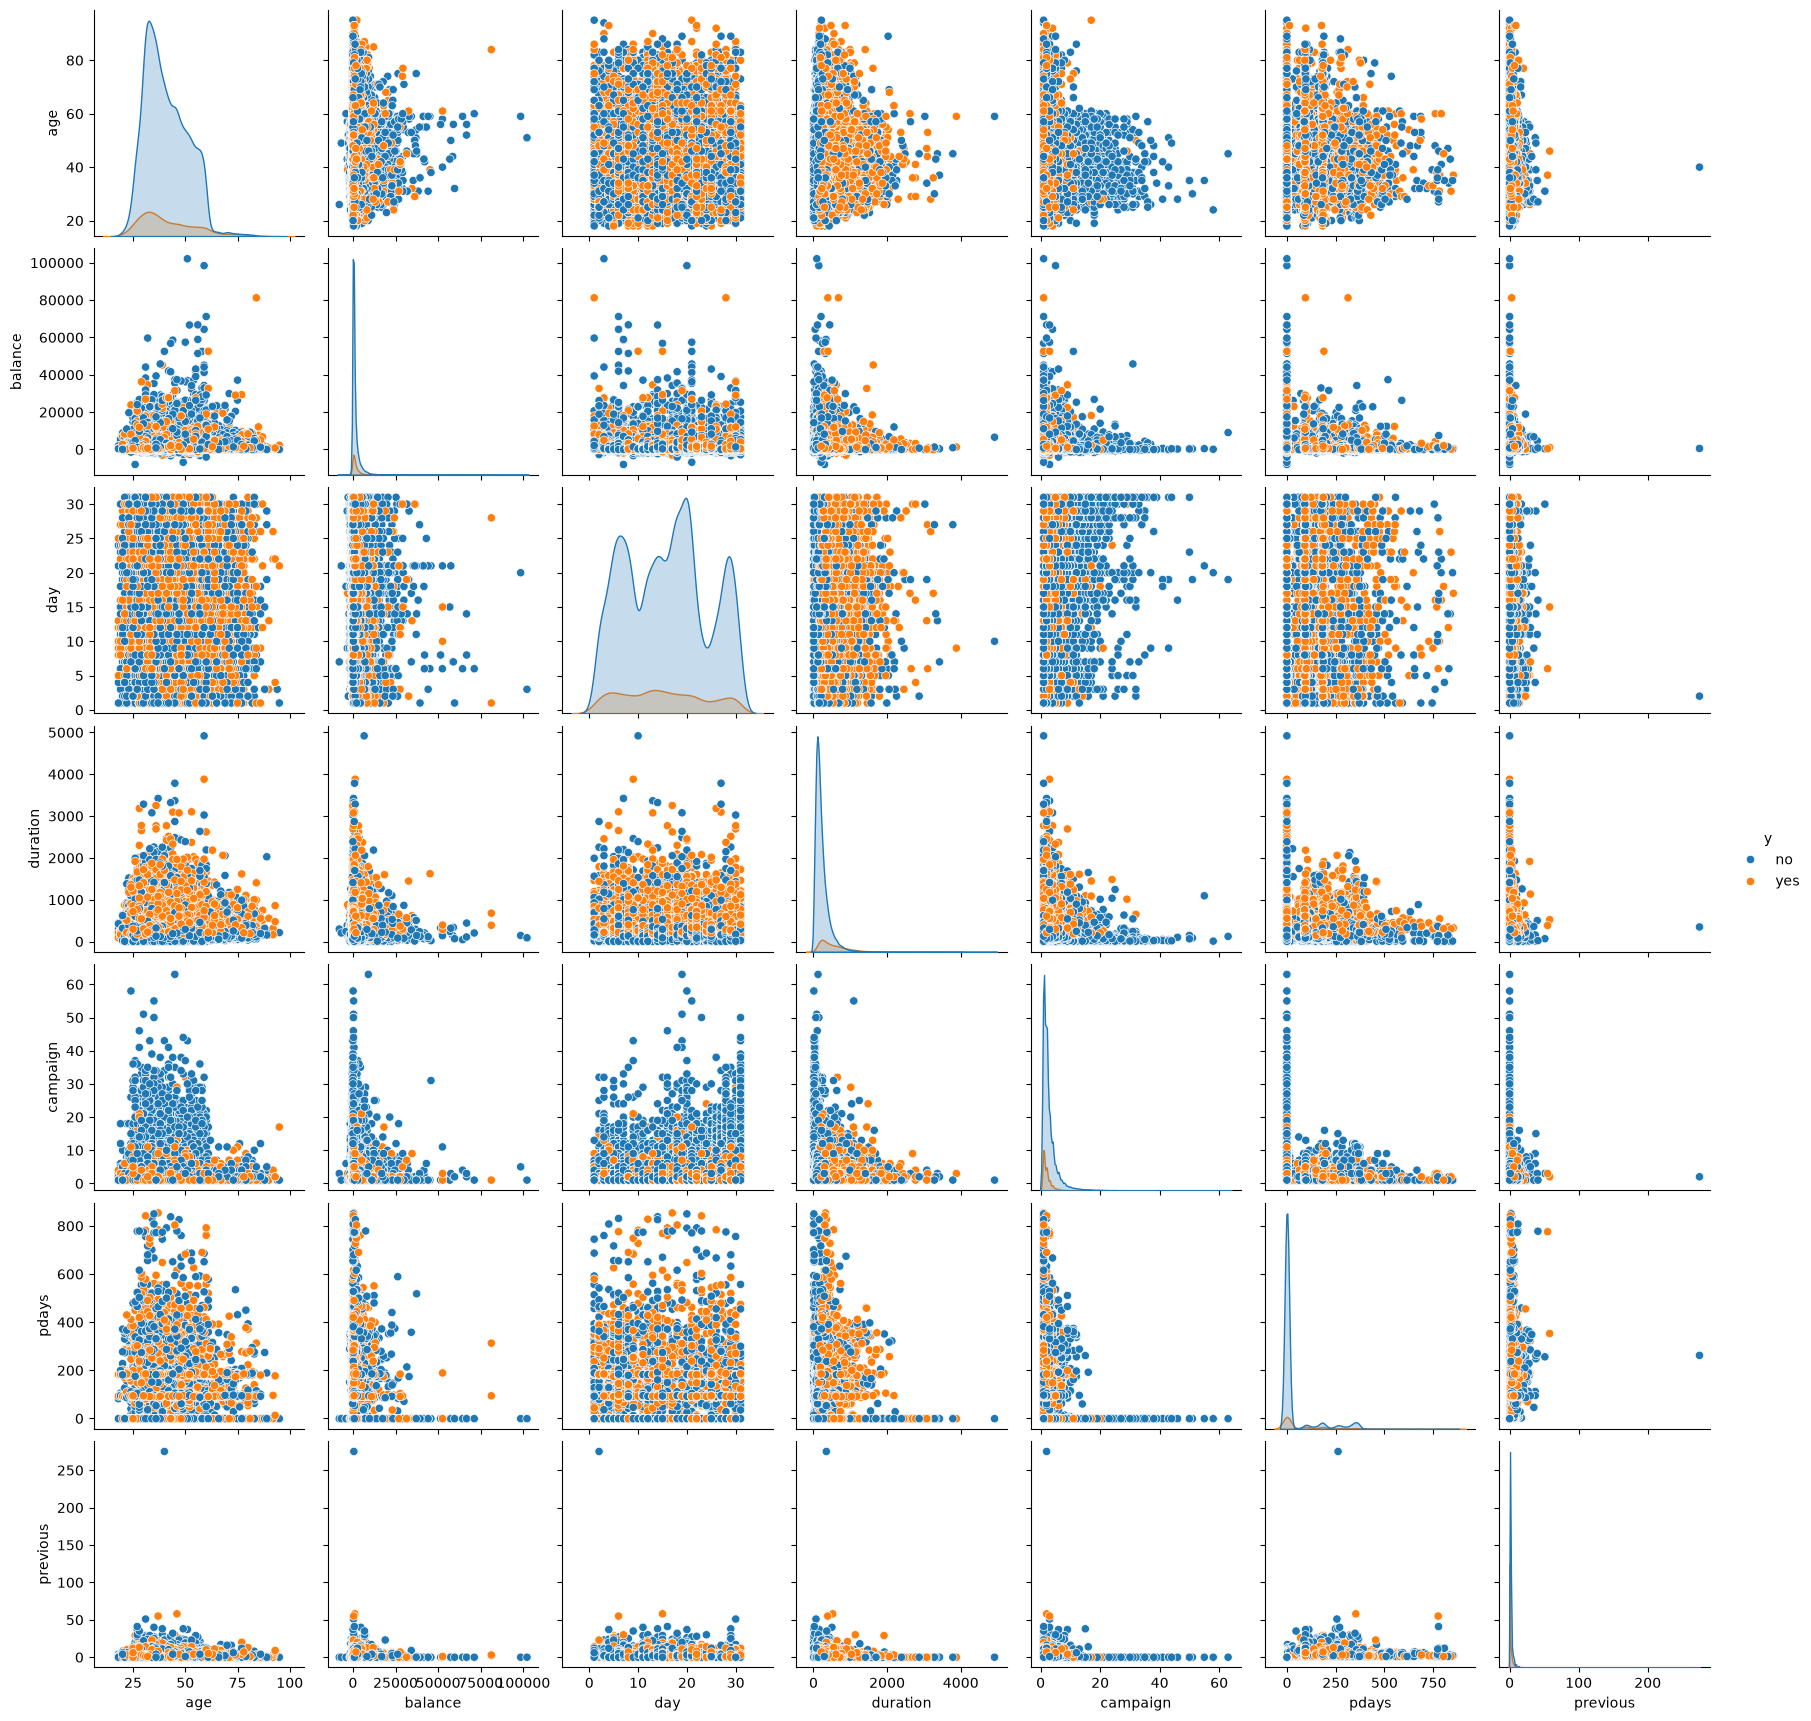

In [3]:
sns.pairplot(df, hue = "y")
plt.show()

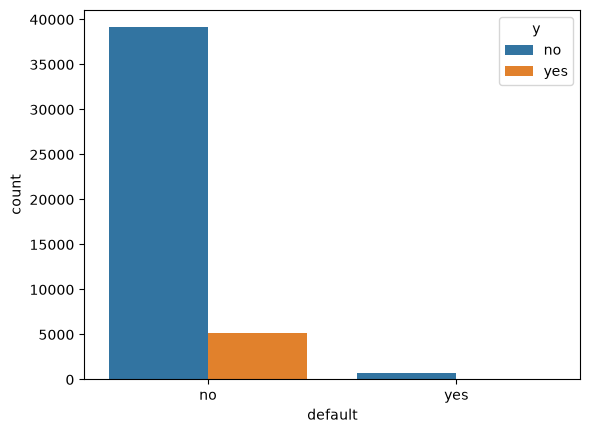

In [4]:
sns.countplot(df, x = "default", hue = "y")
plt.show()

In [5]:
df.groupby("marital")["y"].value_counts(normalize=True)

marital   y  
divorced  no     0.881301
          yes    0.118699
married   no     0.899473
          yes    0.100527
single    no     0.851521
          yes    0.148479
Name: proportion, dtype: float64

In [6]:
df[df["balance"] >= df["balance"].median()]["y"].value_counts()

y
no     19355
yes     3216
Name: count, dtype: int64

In [7]:
df[df["default"] == "yes"]["y"].value_counts(normalize=True)

y
no     0.936196
yes    0.063804
Name: proportion, dtype: float64

In [8]:
df.groupby(["marital", "housing"])["y"].value_counts(normalize=True)

marital   housing  y  
divorced  no       no     0.838710
                   yes    0.161290
          yes      no     0.914945
                   yes    0.085055
married   no       no     0.854237
                   yes    0.145763
          yes      no     0.934483
                   yes    0.065517
single    no       no     0.791780
                   yes    0.208220
          yes      no     0.902351
                   yes    0.097649
Name: proportion, dtype: float64

<Axes: xlabel='housing', ylabel='count'>

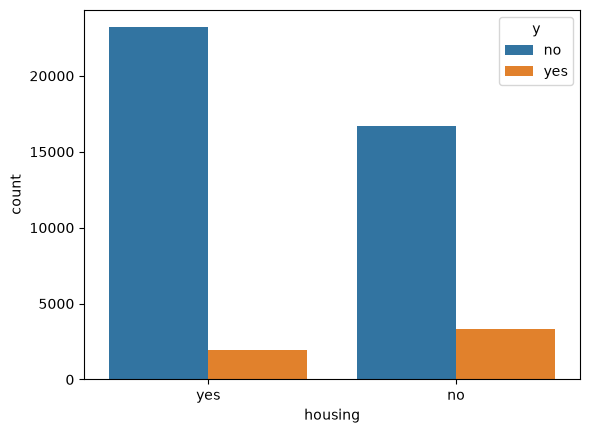

In [9]:
sns.countplot(df, x = "housing", hue = "y")

In [10]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 45111 entries, 0 to 45110
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   age        45111 non-null  int64
 1   job        45111 non-null  str  
 2   marital    45111 non-null  str  
 3   education  45111 non-null  str  
 4   default    45111 non-null  str  
 5   balance    45111 non-null  int64
 6   housing    45111 non-null  str  
 7   loan       45111 non-null  str  
 8   contact    45111 non-null  str  
 9   day        45111 non-null  int64
 10  month      45111 non-null  str  
 11  duration   45111 non-null  int64
 12  campaign   45111 non-null  int64
 13  pdays      45111 non-null  int64
 14  previous   45111 non-null  int64
 15  poutcome   45111 non-null  str  
 16  y          45111 non-null  str  
dtypes: int64(7), str(10)
memory usage: 5.9 MB


In [11]:
df[df["loan"] == "yes"]["y"].value_counts()

y
no     6756
yes     483
Name: count, dtype: int64

In [12]:
df.groupby("contact")["y"].value_counts(normalize=True)

contact    y  
cellular   no     0.851927
           yes    0.148073
telephone  no     0.866161
           yes    0.133839
unknown    no     0.959284
           yes    0.040716
Name: proportion, dtype: float64

In [13]:
df.isnull().sum()

age          0
job          0
marital      0
education    0
default      0
balance      0
housing      0
loan         0
contact      0
day          0
month        0
duration     0
campaign     0
pdays        0
previous     0
poutcome     0
y            0
dtype: int64

In [14]:
df["y"].value_counts()

y
no     39870
yes     5241
Name: count, dtype: int64

## **데이터 분리**

In [15]:
df['y'] = df['y'].map({'yes': 1, 'no': 0})

In [16]:
from sklearn.model_selection import train_test_split

X = df.drop("y", axis = 1)
y = df["y"]

In [17]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.3 , stratify=y, random_state=101)


In [ ]:
X_train = X_train.drop(["duration", "poutcome"], axis = 1)


In [24]:
X_test = X_test.drop(["duration", "poutcome"], axis = 1)

In [25]:
X_train_encoded = pd.get_dummies(X_train, drop_first=True)

In [26]:
X_test_encoded = pd.get_dummies(X_test, drop_first=True)

## **채점용 데이터**

In [18]:
sub = pd.read_csv("bank_submission.csv")
sub.head()

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome
0,64,retired,married,primary,no,445,no,no,cellular,26,oct,338,3,186,1,other
1,24,student,single,secondary,no,1234,no,no,telephone,26,oct,280,2,97,3,success
2,26,management,single,tertiary,no,222,no,no,cellular,26,oct,318,1,120,3,success
3,36,technician,single,secondary,no,204,yes,no,cellular,26,oct,196,1,144,8,other
4,30,management,single,tertiary,no,565,yes,no,cellular,26,oct,104,1,-1,0,unknown


In [4]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score

# ───────── 1. 로드 ─────────
train = pd.read_csv("bank.csv", sep=None, engine="python")
sub   = pd.read_csv("bank_submission.csv", sep=None, engine="python")
y = train.pop("y").map({"yes": 1, "no": 0}).values
MM = {m: i + 1 for i, m in enumerate("jan feb mar apr may jun jul aug sep oct nov dec".split())}

# ───────── 2. 숨은 시간 정보 복원 ─────────
# bank.csv는 날짜순으로 정렬된 파일 -> 월이 크게 되돌아가는 지점이 새 해의 시작 (2008 / 2009 / 2010)
mn = train["month"].map(MM)
blk = mn.rolling(200, center=True, min_periods=1).median().values
drops = np.where(np.diff(blk) < -3)[0]
starts = [d + 1 for i, d in enumerate(drops) if i == 0 or d - drops[i - 1] > 1]   # 연속된 지점은 하나로
year0 = 2008
train["year"] = year0 + np.searchsorted(starts, np.arange(len(train)), side="right")
sub["year"] = train["year"].max()   # 제출 데이터 = 학습 마지막 날 바로 다음 구간(2010-10-26 ~ 11-17)
for d in (train, sub):
    d["date"] = pd.to_datetime(dict(year=d["year"], month=d["month"].map(MM), day=d["day"]))
print(f"연도 경계 행: {starts} | 학습 마지막 날 {train.date.iloc[-1].date()} | 제출 {sub.date.min().date()}~{sub.date.max().date()}")
T0 = train["date"].min()

# ───────── 3. 전처리 ─────────
def fe(d):
    d = d.copy()
    d["t"] = (d["date"] - T0).dt.days                       # 시간 흐름(추세)
    d["dow"] = d["date"].dt.dayofweek                       # 요일
    d["poutcome"] = d["poutcome"].replace({"unknown": "never"})   # unknown = 이전 접촉 없음
    d["pout_ord"] = d["poutcome"].map({"never": 0, "failure": 1, "other": 2, "success": 3})
    d["prev_contacted"] = (d["pdays"] != -1).astype(int)
    d["pdays"] = d["pdays"].replace(-1, np.nan)
    d["bal_neg"] = (d["balance"] < 0).astype(int)
    d["balance"] = np.sign(d["balance"]) * np.log1p(d["balance"].abs())     # 꼬리분포: 로그
    for c in ["campaign", "previous", "pdays", "duration"]: d[c] = np.log1p(d[c])
    d["month_num"] = d["month"].map(MM)
    gap = (np.expm1(d["pdays"]) / 30.4).round()
    d["prev_month"] = ((d["month_num"] - 1 - gap) % 12).where(d["prev_contacted"] == 1)
    d = d.drop(columns=["date"])
    for c in d.select_dtypes("object"): d[c] = d[c].astype("category")
    return d
Xtr, Xsub = fe(train), fe(sub)
for c in Xtr.select_dtypes("category"): Xsub[c] = pd.Categorical(Xsub[c], categories=Xtr[c].cat.categories)
catcols = list(Xtr.select_dtypes("category").columns) + ["dow", "year"]
def dummies(X, cols=None):
    Z = pd.get_dummies(X.astype({c: "object" for c in X.select_dtypes("category")}), columns=catcols).fillna(0).astype(float)
    return Z if cols is None else Z.reindex(columns=cols, fill_value=0)
Ztr = dummies(Xtr); Zsub = dummies(Xsub, Ztr.columns)

# ───────── 4. 모델: HGB + RandomForest (2009~2010 데이터만 학습) ─────────
def fit_predict(a_idx, X_te, Z_te):
    p_h = np.mean([HistGradientBoostingClassifier(categorical_features="from_dtype", learning_rate=0.05, max_iter=200,
                   max_leaf_nodes=8, min_samples_leaf=30, l2_regularization=2, random_state=s
                   ).fit(Xtr.iloc[a_idx], y[a_idx]).predict_proba(X_te)[:, 1] for s in range(2)], axis=0)
    p_r = RandomForestClassifier(200, min_samples_leaf=3, max_features=0.3, n_jobs=-1, random_state=0
                   ).fit(Ztr.iloc[a_idx], y[a_idx]).predict_proba(Z_te)[:, 1]
    return 0.5 * p_h + 0.5 * p_r
recent = lambda n: np.where(train["year"].values[:n] >= 2009)[0]

# ───────── 5. 시간 기준 검증: 과거로 학습 -> 바로 다음 250건 예측 (제출 상황과 동일) ─────────
N = len(train); folds = [(N - 1000, N - 750), (N - 750, N - 500), (N - 500, N - 250), (N - 250, N)]
oof, ys = [], []
for a, b in folds:
    oof.append(fit_predict(recent(a), Xtr.iloc[a:b], Ztr.iloc[a:b])); ys.append(y[a:b])
oof, ys = np.concatenate(oof), np.concatenate(ys)
print(f"시간 기준 검증 AUC {roc_auc_score(ys, oof):.4f} (구간별 yes 비율 평균 {ys.mean():.2f})")
ths = np.arange(0.30, 0.71, 0.01)
acc = np.array([accuracy_score(ys, oof > t) for t in ths])
th = float(ths[3:-3][np.argmax(np.convolve(acc, np.ones(7) / 7, mode="same")[3:-3])])   # 평활화한 최적점
print(f"threshold {th:.2f} -> 검증 정확도 {accuracy_score(ys, oof > th):.3f}, F1 {f1_score(ys, oof > th):.3f}")

# ───────── 6. 최종 학습 + 제출 ─────────
p = fit_predict(recent(N), Xsub, Zsub)
pred = np.where(p > th, "yes", "no")
pd.DataFrame({"y": pred}).to_csv("bank_final_submission.csv", index=False)
print(f"제출 예측 yes 비율 {np.mean(pred == 'yes'):.2f} (평균 예측확률 {p.mean():.2f}) / 저장 완료")

연도 경계 행: [np.int64(27729), np.int64(42591)] | 학습 마지막 날 2010-10-25 | 제출 2010-10-26~2010-11-17
시간 기준 검증 AUC 0.8542 (구간별 yes 비율 평균 0.50)
threshold 0.56 -> 검증 정확도 0.778, F1 0.790
제출 예측 yes 비율 0.50 (평균 예측확률 0.53) / 저장 완료
